In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv('../DATA/Featured_Data/gurgaon_properties_missing_value_imputation.csv')

In [3]:
df.shape

(3571, 18)

In [4]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,signature global park 4,sector 36,0.82,7586.0,3,2,2,2.0,New Property,850.0,0,0,0,0,0,0,8
1,flat,smart world gems,sector 89,0.95,8597.0,2,2,2,4.0,New Property,1226.0,1,1,0,0,0,0,38
2,flat,breez global hill view,sohna road,0.32,5470.0,2,2,1,17.0,New Property,1000.0,0,0,0,0,0,0,49
3,flat,bestech park view sanskruti,sector 92,1.60,8020.0,3,4,3+,10.0,Relatively New,1615.0,0,1,0,0,1,1,174
4,flat,suncity avenue,sector 102,0.48,9023.0,2,2,1,5.0,Relatively New,582.0,0,0,1,0,0,0,159


In [5]:
latlong = pd.read_csv('../DATA/Featured_Data/gurgaon_sectors_coordinates_latlong.csv')

In [6]:
latlong.rename(columns={'Sector': 'sector', 'Latitude': 'latitude', 'Longitude': 'longitude'}, inplace=True)


In [7]:
latlong['sector'] = latlong['sector'].str.lower()   

In [8]:
# drop these Matched Location	Status columns
latlong.drop(columns=['Matched Location', 'Status'], axis=1, inplace=True)
latlong.head()

,sector,latitude,longitude
0,sector 1,28.360102,76.948375
1,sector 2,28.509050,77.034283
2,sector 3,28.497391,77.020526
3,sector 4,28.475006,77.010353
4,sector 5,28.367354,76.926724


In [9]:
latlong

,sector,latitude,longitude
0,sector 1,28.360102,76.948375
1,sector 2,28.509050,77.034283
2,sector 3,28.497391,77.020526
3,sector 4,28.475006,77.010353
4,sector 5,28.367354,76.926724
...,...,...,...
110,sector 111,28.522277,77.033620
111,sector 112,28.520340,77.018861
112,sector 113,28.528665,77.025028
113,sector 114,28.531878,77.011779


In [10]:
new_df = df.merge(latlong, on='sector')

In [11]:
new_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3157 entries, 0 to 3156
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   property_type    3157 non-null   object 
 1   society          3157 non-null   object 
 2   sector           3157 non-null   object 
 3   price            3157 non-null   float64
 4   price_per_sqft   3157 non-null   float64
 5   bedRoom          3157 non-null   int64  
 6   bathroom         3157 non-null   int64  
 7   balcony          3157 non-null   object 
 8   floorNum         3157 non-null   float64
 9   agePossession    3157 non-null   object 
 10  built_up_area    3157 non-null   float64
 11  study room       3157 non-null   int64  
 12  servant room     3157 non-null   int64  
 13  store room       3157 non-null   int64  
 14  pooja room       3157 non-null   int64  
 15  others           3157 non-null   int64  
 16  furnishing_type  3157 non-null   int64  
 17  luxury_score  

In [12]:
new_df.columns

Index(['property_type', 'society', 'sector', 'price', 'price_per_sqft',
       'bedRoom', 'bathroom', 'balcony', 'floorNum', 'agePossession',
       'built_up_area', 'study room', 'servant room', 'store room',
       'pooja room', 'others', 'furnishing_type', 'luxury_score', 'latitude',
       'longitude'],
      dtype='object')

In [13]:
group_df = new_df.groupby('sector').mean(numeric_only=True)[['price','price_per_sqft','built_up_area','latitude','longitude']]

In [14]:
group_df

,price,price_per_sqft,built_up_area,latitude,longitude
sector,,,,,
sector 1,1.860000,8249.833333,2327.833333,28.360102,76.948375
sector 10,2.092857,11866.571429,1908.857143,28.444581,77.006023
sector 102,1.696636,10603.822430,1556.130841,28.475487,76.971175
sector 103,1.495000,7445.785714,1865.428571,28.493087,76.986645
sector 104,1.605147,8922.250000,1833.029412,28.479532,76.993720
...,...,...,...,...,...
sector 91,1.648235,7586.117647,2028.647059,28.400759,76.921080
sector 92,0.934000,5928.290000,1571.341800,28.408905,76.915523
sector 93,0.848889,8009.888889,1017.000000,28.415605,76.931638


In [22]:
import plotly.express as px

fig = px.scatter_map(
    group_df.reset_index(),
    lat="latitude",
    lon="longitude",
    color="price_per_sqft",
    size="built_up_area",
    hover_name="sector",
    color_continuous_scale="RdYlBu_r",
    zoom=10,
    center={"lat": 28.45, "lon": 76.98},
    map_style="open-street-map",
    size_max=20
)

fig.update_layout(
    coloraxis_colorbar=dict(
        title="Price per Sqft",
        ticks="outside"
    )
)

fig.show()

In [23]:
new_df.to_csv('../DATA/Model_Data/data_viz1.csv',index=False)

In [24]:
df1 = pd.read_csv('../DATA/Preprocessed_Data/gurgaon_properties.csv')

In [25]:
df1.head()

,property_name,property_type,society,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,address,floorNum,facing,agePossession,nearbyLocations,description,furnishDetails,features,rating
0,3 BHK Flat in Sector 36 Sohna,flat,signature global park 4,0.82,7585.0,1081.0,Super Built up area 1081(100.43 sq.m.)Carpet a...,3,2,2,not available,"144, Sector 36 Sohna, Gurgaon, Haryana",2.0,NaN,0 to 1 Year Old,"['Sector 55-56 Metro Station', 'The Leaf Mall ...",We need to shift somewhere else,NaN,"['Lift(s)', 'Park']",NaN
1,2 BHK Flat in Sector 89 Gurgaon,flat,smart world gems,0.95,8600.0,1105.0,Carpet area: 1103 (102.47 sq.m.),2,2,2,"study room,servant room","O 118d, Sector 89 Gurgaon, Gurgaon, Haryana",4.0,NaN,Within 6 months,"['Sant Soordas Sihi Metro Station', 'Airia Mal...",Smartworld gem4 th floor new construction,NaN,"['Power Back-up', 'Intercom Facility', 'Lift(s...","['Environment4 out of 5', 'Lifestyle4 out of 5..."
2,2 BHK Flat in Sector 86 Gurgaon,flat,pyramid elite,0.46,79.0,58228.0,Carpet area: 58141 (5401.48 sq.m.),2,2,1,not available,"Sector 86 Gurgaon, Gurgaon, Haryana",0.0,NaN,Under Construction,"['V3S Sapphire Ninety Mall', 'Sector 86 Road',...",Near to dwarka expressway\nNear to airport,[],"['Intercom Facility', 'Lift(s)', 'Park']","['Environment5 out of 5', 'Safety4.5 out of 5'..."
3,2 BHK Flat in Sohna,flat,breez global hill view,0.32,5470.0,585.0,Built Up area: 1000 (92.9 sq.m.)Carpet area: 5...,2,2,1,not available,"1701 & 1708, Sohna, Gurgaon, Haryana",17.0,NaN,0 to 1 Year Old,"['Huda City Centre', 'Omaxe City Centre', 'Nin...",Both adjacent properties available which can b...,[],"['Feng Shui / Vaastu Compliant', 'Security / F...","['Safety4 out of 5', 'Lifestyle4 out of 5', 'E..."
4,3 BHK Flat in Sector 92 Gurgaon,flat,bestech park view sanskruti,1.60,8020.0,1995.0,Super Built up area 1995(185.34 sq.m.)Built Up...,3,4,3+,"servant room,others","Sector 92 Gurgaon, Gurgaon, Haryana",10.0,North-West,1 to 5 Year Old,"['Sapphire 93 Mall', 'Dwarka Expressway', 'NH-...",Check out this 3 bhk apartment for sale in bes...,"['3 Wardrobe', '6 Fan', '1 Exhaust Fan', '3 Ge...","['Centrally Air Conditioned', 'Water purifier'...","['Green Area5 out of 5', 'Construction5 out of..."


In [37]:
wordcloud_df = df1.merge(df, left_index=True, right_index=True)[['sector','features']]

In [39]:
wordcloud_df

,sector,features
0,sector 36,"['Lift(s)', 'Park']"
1,sector 89,"['Power Back-up', 'Intercom Facility', 'Lift(s..."
2,sohna road,"['Intercom Facility', 'Lift(s)', 'Park']"
3,sector 92,"['Feng Shui / Vaastu Compliant', 'Security / F..."
4,sector 102,"['Centrally Air Conditioned', 'Water purifier'..."
...,...,...
3566,sector 84,"['Security / Fire Alarm', 'Feng Shui / Vaastu ..."
3567,sector 109,"['Power Back-up', 'Private Garden / Terrace', ..."
3568,sector 2,"['Feng Shui / Vaastu Compliant', 'Private Gard..."
3569,sector 43,"['Security / Fire Alarm', 'Lift(s)', 'Maintena..."


In [41]:
wordcloud_df.groupby('sector')

In [44]:
wordcloud_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3571 entries, 0 to 3570
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sector    3571 non-null   object
 1   features  2938 non-null   object
dtypes: object(2)
memory usage: 83.7+ KB


In [63]:
import ast

wordcloud_df['features'] = wordcloud_df['features'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

new = wordcloud_df.groupby('sector')['features'].sum().reset_index()

In [64]:
new

,sector,features
0,dwarka expressway,"[Security / Fire Alarm, Feng Shui / Vaastu Com..."
1,gwal pahari,"[Centrally Air Conditioned, Water purifier, Se..."
2,manesar,"[Power Back-up, Lift(s), Swimming Pool, Park, ..."
3,sector 1,"[Security / Fire Alarm, Feng Shui / Vaastu Com..."
4,sector 10,"[Feng Shui / Vaastu Compliant, Private Garden ..."
...,...,...
99,sector 92,"[Feng Shui / Vaastu Compliant, Security / Fire..."
100,sector 93,"[Power Back-up, Feng Shui / Vaastu Compliant, ..."
101,sector 95,"[Security / Fire Alarm, Power Back-up, Lift(s)..."
102,sector 99,"[Security / Fire Alarm, Feng Shui / Vaastu Com..."


'Feng Shui / Vaastu Compliant'

In [28]:
import ast
main = []
for item in wordcloud_df['features'].dropna().apply(ast.literal_eval):
    main.extend(item)

In [29]:
main

['Lift(s)',
 'Park',
 'Power Back-up',
 'Intercom Facility',
 'Lift(s)',
 'Swimming Pool',
 'Park',
 'Piped-gas',
 'Internet/wi-fi connectivity',
 'Fitness Centre / GYM',
 'Club house / Community Center',
 'Intercom Facility',
 'Lift(s)',
 'Park',
 'Feng Shui / Vaastu Compliant',
 'Security / Fire Alarm',
 'Intercom Facility',
 'Lift(s)',
 'Maintenance Staff',
 'Water Storage',
 'Park',
 'Visitor Parking',
 'Centrally Air Conditioned',
 'Water purifier',
 'Security / Fire Alarm',
 'Feng Shui / Vaastu Compliant',
 'Private Garden / Terrace',
 'Intercom Facility',
 'Lift(s)',
 'High Ceiling Height',
 'Maintenance Staff',
 'False Ceiling Lighting',
 'Water Storage',
 'Separate entry for servant room',
 'No open drainage around',
 'Bank Attached Property',
 'Piped-gas',
 'Internet/wi-fi connectivity',
 'Recently Renovated',
 'Visitor Parking',
 'Swimming Pool',
 'Park',
 'Security Personnel',
 'Natural Light',
 'Airy Rooms',
 'Spacious Interiors',
 'Low Density Society',
 'Waste Disposal',

In [30]:
from wordcloud import WordCloud

In [31]:
feature_text = ' '.join(main)

In [33]:
import pickle
pickle.dump(feature_text, open('../DATA/Model_Data/feature_text.pkl','wb'))

In [34]:
feature_text

'Lift(s) Park Power Back-up Intercom Facility Lift(s) Swimming Pool Park Piped-gas Internet/wi-fi connectivity Fitness Centre / GYM Club house / Community Center Intercom Facility Lift(s) Park Feng Shui / Vaastu Compliant Security / Fire Alarm Intercom Facility Lift(s) Maintenance Staff Water Storage Park Visitor Parking Centrally Air Conditioned Water purifier Security / Fire Alarm Feng Shui / Vaastu Compliant Private Garden / Terrace Intercom Facility Lift(s) High Ceiling Height Maintenance Staff False Ceiling Lighting Water Storage Separate entry for servant room No open drainage around Bank Attached Property Piped-gas Internet/wi-fi connectivity Recently Renovated Visitor Parking Swimming Pool Park Security Personnel Natural Light Airy Rooms Spacious Interiors Low Density Society Waste Disposal Rain Water Harvesting Water softening plant Shopping Centre Fitness Centre / GYM Club house / Community Center Centrally Air Conditioned Water purifier Security / Fire Alarm Feng Shui / Vaas

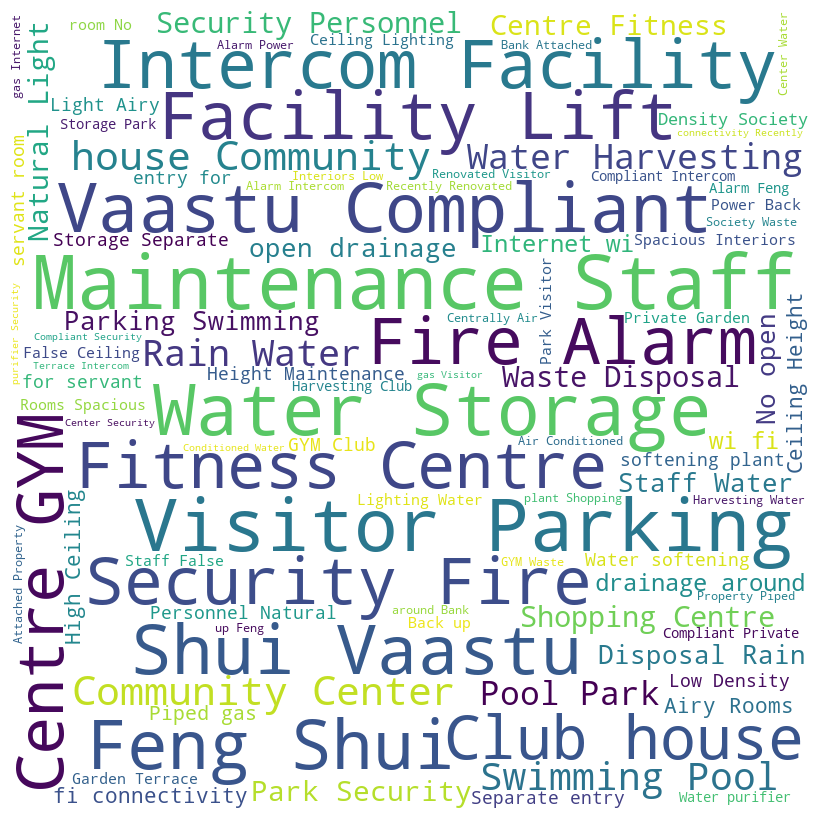

In [35]:
plt.rcParams["font.family"] = "Arial"

wordcloud = WordCloud(width = 800, height = 800, 
                      background_color ='white', 
                      stopwords = set(['s']),  # Any stopwords you'd like to exclude
                      min_font_size = 10).generate(feature_text)

plt.figure(figsize = (8, 8), facecolor = None) 
plt.imshow(wordcloud, interpolation='bilinear') 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.show() # st.pyplot()

In [36]:
data = dict(
    names=["A", "B", "C", "D", "E", "F"],
    parents=["", "", "", "A", "A", "C"],
    values=[10, 20, 30, 40, 50, 60],
)

fig = px.sunburst(
    df1,
    names='property_type',
    values='price_per_sqft',
    parents='bedRoom',
    title="Sample Sunburst Chart"
)
fig.show()

In [144]:
fig = px.scatter(df, x="built_up_area", y="price", color="bedRoom", title="Area Vs Price")

# Show the plot
fig.show()

In [105]:
fig = px.pie(df, names='bedRoom', title='Total Bill Amount by Day')

# Show the plot
fig.show()

In [109]:
temp_df = df[df['bedRoom'] <= 4]
# Create side-by-side boxplots of the total bill amounts by day
fig = px.box(temp_df, x='bedRoom', y='price', title='BHK Price Range')

# Show the plot
fig.show()


C:\Users\Nitish\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning:

`distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).

C:\Users\Nitish\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning:

`distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).



<AxesSubplot:xlabel='price', ylabel='Density'>

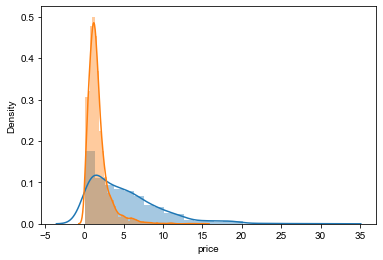

In [111]:
sns.distplot(df[df['property_type'] == 'house']['price'])
sns.distplot(df[df['property_type'] == 'flat']['price'])

In [150]:
new_df['sector'].unique().tolist().insert(0,'overall')